In [1]:
import glob
import openmc
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import LogNorm
import math
import os

In [ ]:
### Choose whether to use the photonuclear cross section library or not
PHOTONUCLEAR = True

if PHOTONUCLEAR:
    # Library with photonuclear data (with folder photonuclear/)
    CROSS_SECTIONS = "/Users/loren/WORKSPACE/xs/OpenMC/mcnp_endfb71/cross_sections.xml"
else:
    # Library without photonuclear data, readable from the official release
    # (e.g., endfb-vii.1-hdf5 downloaded from openmc.org)
    CROSS_SECTIONS = "/Users/loren/WORKSPACE/xs/OpenMC/endfb-vii.1-hdf5/cross_sections.xml"

In [ ]:
###############################################################################
# MATERIALS
###############################################################################

stilbene = openmc.Material(name='stilbene', material_id=99)
stilbene.set_density('g/cm3', 1.16)
stilbene.add_nuclide('C0', .5385)
stilbene.add_nuclide('H1', .4615)

air = openmc.Material(name='air')
air.set_density('g/cm3', 0.00000000000001225)
air.add_nuclide('N14', 0.78)
air.add_nuclide('O16', 0.21)

materials = openmc.Materials([stilbene, air])
materials.cross_sections = CROSS_SECTIONS
materials.export_to_xml()

In [3]:
###############################################################################
# GEOMETRY
###############################################################################
radius = 5.08 / 2  # cm
length = 5.08 

cylinder_s = openmc.ZCylinder(r=radius)
bottom_s = openmc.ZPlane(z0=0)
top_s = openmc.ZPlane(z0=length)
air_s = openmc.Sphere(r=8, boundary_type='vacuum')  

stilbene_cell = openmc.Cell(fill=stilbene, region=-cylinder_s & +bottom_s & -top_s, cell_id = 20)   
air_cell = openmc.Cell(fill=air, region= -air_s & ~stilbene_cell.region)

universe = openmc.Universe(cells=[stilbene_cell, air_cell])

geometry = openmc.Geometry(universe)
geometry.export_to_xml()

In [4]:
# plot = openmc.SlicePlot()
# plot.basis = 'xz'
# plot.origin=(0.0, 0.0, 0.0)
# plot.width=(10.0, 10.0)
# plot.pixels=(500, 500)


# plot.color_by = 'material'

# plots = openmc.Plots([plot])
# plots.export_to_xml()

# openmc.plot_geometry()

In [ ]:
###############################################################################
# SETTINGS
###############################################################################

settings = openmc.Settings()
settings.run_mode = 'fixed source'

settings.seed = 42 # np.random.randint(1, int(1e6)) 
source = openmc.IndependentSource()

# -----------------------------------------------------------------------------
# 1. SPATIAL DISTRIBUTION: Point
# -----------------------------------------------------------------------------
source.space = openmc.stats.Point(xyz=(0.0, 0.0, -1.0))

# -----------------------------------------------------------------------------
# 2. ANGULAR DISTRIBUTION: Monodirectional
# -----------------------------------------------------------------------------
source.angle = openmc.stats.Monodirectional(reference_uvw=(0.0, 0.0, 1.0))

# -----------------------------------------------------------------------------
# 3. ENERGY & TRACKING
# -----------------------------------------------------------------------------
energy_dist = openmc.stats.Watt(a=1.025e6, b=2.926e-6)
source.energy = energy_dist
source.particle = 'neutron'
settings.source = source

n_batches = 100
n_particles = 4000

settings.batches = n_batches
settings.particles = n_particles
settings.photon_transport = True
if PHOTONUCLEAR:
    if not hasattr(openmc.Settings, "photonuclear_physics"):
        raise RuntimeError(
            "PHOTONUCLEAR = True, but this OpenMC build has no photonuclear "
            "physics: install the photonuclear-physics branch or set "
            "PHOTONUCLEAR = False.")
    settings.photonuclear_physics = True
    settings.energy_max = {"photon": 100E6, "neutron": 20E6}

settings.max_tracks = int(n_batches * n_particles)

settings.export_to_xml()

Plot Cf252 energy distribution

/Users/loren/miniconda3/envs/openmc-pn/lib/python3.14/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


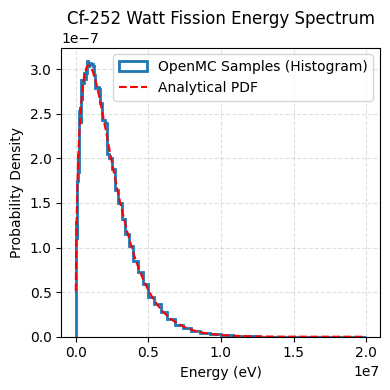

In [6]:
# 2. Sample the distribution (generates a 1-D numpy array of energies in eV)
num_samples = 100000
sampled_energies = energy_dist.sample(n_samples=num_samples)

# 3. Create log-spaced bins (e.g., from 10 keV to 20 MeV)
bins = np.logspace(4, 7.3, 100)

# 4. Plot the sampled histogram
plt.figure(figsize=(4, 4))
plt.hist(sampled_energies, bins=bins, density=True, histtype='step', 
         linewidth=2, label='OpenMC Samples (Histogram)')

# 5. Overlay the analytical Watt PDF formula for comparison
E = np.logspace(4, 7.3, 500)
a = 1.025e6
b = 2.926e-6

# Unnormalized analytical PDF
pdf_analytical = np.exp(-E / a) * np.sinh(np.sqrt(b * E))

# Normalize numerically using the trapezoidal rule
pdf_analytical /= np.trapezoid(pdf_analytical, E) 

plt.plot(E, pdf_analytical, color='red', linestyle='--', label='Analytical PDF')

# 6. Format the plot
#plt.xscale('log')
#plt.yscale("log")
plt.xlabel('Energy (eV)')
plt.ylabel('Probability Density')
plt.title('Cf-252 Watt Fission Energy Spectrum')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [7]:
###############################################################################
# RUN
###############################################################################

openmc.run(tracks=True)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [ ]:
save_folder = "/Volumes/PortableSSD/DATA/2026/UM-OPENMC-PYMPPOST-METHODOLOGY/trans-stilbene/252Cf/"

print(f"Moving statepoint file to results directory with name OpenMC_tracks_{settings.particles * settings.batches / 1E5}E5.h5")
os.system(f"mv ./tracks.h5 {save_folder}OpenMC_tracks_{int(settings.particles * settings.batches) / 1E5}E5.h5")
os.system("rm statepoint.100.h5 summary.h5")

Moving statepoint file to results directory with name OpenMC_tracks_4.0E5.h5


0